# Mixed-species group properties (group size 16, 8 + 8 fish)

One figure, 3 rows x 4 columns (pairs TB+RB, BPT+ST, NT+ST, NT+RET; species A = first species of the pair):
1. **Individual speed** of the two species subgroups (solid) and the entire group (dotted), with box plots of the subgroups.
2. **Group polarization** of the two subgroups, the entire group and a **random subgroup** (8 fish chosen at random in every frame, ignoring species; dashed grey).
3. **Subgroup centroid distance**, observed (black) vs a label-shuffle null (grey: species labels shuffled 1000 times per frame), with box plots.

Y axis = probability density. Frames need at least 75 % of the fish tracked (polarization; centroid distance: 75 % of each subgroup).
Data: TB8+RB8 from `TBRB16_traj_bl.csv` (species in `SPECIES ID`), other pairs from `*_traj_bl.npz` (first 8 fish = species A).
Centroid distance uses one frame every 3 s for the npz trials and all frames of the csv.
Saved as `Results/mixed_species_group_properties_gs16` (PNG and PDF, 300 dpi).

## 1. Settings and functions

In [1]:
%matplotlib inline
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"]})

DATA, OUT = os.path.join("..", "Data"), os.path.join("..", "Results")
PAIRS = [("TB", "RB"), ("BPT", "ST"), ("NT", "ST"), ("NT", "RET")]            # (species A, species B), one column each
COL = {"A": "#E69F00", "B": "#0072B2", "ALL": "k", "obs": "k", "null": "grey", "rand8": "grey"}
rng, rng_rand = np.random.default_rng(0), np.random.default_rng(1)        # null shuffles, random 8 fish
FONT, TICK_FONT, lw = 13, 10, 1.2                                          # labels (pt), ticks (pt), line width

def rel_hist(ax, x, edges, **kw):
    """Step histogram of the probability density; returns the bar heights."""
    return ax.hist(x, bins=edges, density=True, histtype="step", **kw)[0]


def visible_max(h, edges, xl):
    """Tallest bar inside the x range xl."""
    return h[(edges[:-1] < xl[1]) & (edges[1:] > xl[0])].max()


def set_y_to_max(ax, ymax):
    """y axis from 0 to the tallest bar; whole-number ticks in 2-3 equal steps when ymax >= 2, otherwise 0, ymax/2, ymax."""
    ax.set_ylim(0, ymax)
    if ymax >= 2:
        top = int(ymax)
        while top % 2 and top % 3: top -= 1
        yt = list(range(0, top + 1, top // 2 if top % 2 == 0 else top // 3))
        ax.set_yticks(yt); ax.set_yticklabels(map(str, yt))
    else:
        d = 1 if ymax >= 0.2 else 2 if ymax >= 0.02 else 3 if ymax >= 0.002 else 4   # decimals of the tick labels
        ax.set_yticks([0, ymax / 2, ymax]); ax.set_yticklabels(["0", f"{ymax / 2:.{d}f}", f"{ymax:.{d}f}"])


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=TICK_FONT)


def box_stats(x, label):
    q1, med, q3 = np.percentile(x, [25, 50, 75]); iqr = q3 - q1
    return dict(label=label, med=med, q1=q1, q3=q3, fliers=[], whislo=x[x >= q1 - 1.5 * iqr].min(), whishi=x[x <= q3 + 1.5 * iqr].max())


def box_stats_from_counts(counts, edges, label):
    """Box-plot statistics of values stored as histogram counts on `edges`."""
    cdf = np.concatenate([[0.0], np.cumsum(counts) / np.sum(counts)])
    q1, med, q3 = np.interp([0.25, 0.5, 0.75], cdf, edges); iqr = q3 - q1
    nz = np.nonzero(counts)[0]
    return dict(label=label, med=med, q1=q1, q3=q3, fliers=[],
                whislo=max(q1 - 1.5 * iqr, edges[nz[0]]), whishi=min(q3 + 1.5 * iqr, edges[nz[-1] + 1]))


def draw_box(axb, stats, colors):
    """Horizontal box plots (no outliers) under a histogram."""
    bp = axb.bxp(stats, vert=False, showfliers=False, widths=0.65, patch_artist=True, medianprops=dict(color="k", lw=lw * 0.8))
    for box, c in zip(bp["boxes"], colors):
        box.set_facecolor(c); box.set_alpha(0.6)
    axb.invert_yaxis(); axb.set_yticks([])
    axb.spines[["top", "right", "left"]].set_visible(False)
    axb.tick_params(labelsize=TICK_FONT)


def hist_and_box(fig, spec, hist_h, box_h):
    """A histogram axis with a box-plot axis below it (shared x)."""
    inner = GridSpecFromSubplotSpec(2, 1, subplot_spec=spec, height_ratios=[hist_h, box_h], hspace=0.2 / hist_h)
    ax = fig.add_subplot(inner[0])
    return ax, fig.add_subplot(inner[1], sharex=ax)


def polarization(vel, mask=None):
    """Length of the mean unit heading of the fish in `mask` (all if None) per frame; NaN if fewer than 75 % of them have a heading."""
    mask = np.ones(vel.shape[:2], bool) if mask is None else mask
    speed = np.linalg.norm(vel, axis=2)
    ok = np.isfinite(speed) & (speed > 1e-9) & mask
    u = np.where(ok[..., None], vel / np.where(ok, speed, 1.0)[..., None], 0.0)
    n = ok.sum(1)
    P = np.linalg.norm(u.sum(1), axis=1) / np.maximum(n, 1)
    P[n < np.maximum(2, np.ceil(0.75 * mask.sum(1)))] = np.nan
    return P


def centroid_trial(pos, is_a):
    """Frames with >= 75 % of each subgroup tracked: observed centroid distance and what the null needs."""
    valid = np.isfinite(pos).all(axis=2)
    wA, wB = valid & is_a, valid & ~is_a
    ok = (wA.sum(1) >= np.ceil(0.75 * is_a.sum(1))) & (wB.sum(1) >= np.ceil(0.75 * (~is_a).sum(1)))
    pos0, valid, wA, wB = np.where(valid[..., None], pos, 0.0)[ok], valid[ok], wA[ok], wB[ok]
    obs = np.linalg.norm((pos0 * wA[..., None]).sum(1) / wA.sum(1)[:, None] - (pos0 * wB[..., None]).sum(1) / wB.sum(1)[:, None], axis=1)
    return dict(pos0=pos0, valid=valid, nA=wA.sum(1), nB=wB.sum(1), obs=obs)


def null_counts(tr, edges, K=1000, chunk=8_000_000):
    """Shuffle the species labels among the tracked fish of each frame K times -> histogram counts of the centroid distance."""
    pos0, valid, nA, nB = tr["pos0"], tr["valid"], tr["nA"], tr["nB"]
    T, N = valid.shape
    step, counts = max(1, chunk // (K * N)), np.zeros(len(edges) - 1, np.int64)
    for s in range(0, T, step):
        e = min(T, s + step)
        a, b = nA[s:e, None, None], nB[s:e, None, None]
        rank = np.where(valid[s:e, None, :], rng.random((e - s, K, N), dtype=np.float32), np.float32(np.inf)).argsort(2).argsort(2)
        P = pos0[s:e].astype(np.float32)
        d = np.linalg.norm(((rank < a).astype(np.float32) @ P) / a - (((rank >= a) & (rank < a + b)).astype(np.float32) @ P) / b, axis=2)
        counts += np.histogram(d.ravel(), bins=edges)[0]
    return counts

## 2. Load the mixed trials (the 1000-shuffle null takes a few minutes)

In [2]:
def trials(a, b):
    """(positions, velocities, is_a, frame step for the centroid distance) of every mixed trial of a pair."""
    if (a, b) == ("TB", "RB"):
        for _, g in pd.read_csv(os.path.join(DATA, "TBRB16_traj_bl.csv")).groupby("Replicate", sort=False):
            T = len(g) // 16                                                # 16 rows per frame
            is_a = (g["SPECIES ID"].astype(str).str.strip().to_numpy()[:T * 16] == a).reshape(T, 16)
            yield g[["x", "y"]].to_numpy(float)[:T * 16].reshape(T, 16, 2), g[["vx", "vy"]].to_numpy(float)[:T * 16].reshape(T, 16, 2), is_a, 1
    else:
        for f in sorted(glob.glob(os.path.join(DATA, f"{a}8{b}8_*_traj_bl.npz")) + glob.glob(os.path.join(DATA, f"{b}8{a}8_*_traj_bl.npz"))):
            z = np.load(f)
            pos = z["positions"].astype(float)
            yield pos, z["velocities"].astype(float), np.tile(np.arange(pos.shape[1]) < 8, (len(pos), 1)), 75   # one frame every 3 s


res = {}
for a, b in PAIRS:
    k = dict(speed_A=[], speed_B=[], pol=[], pol_A=[], pol_B=[], pol_rand8=[])
    cd = []
    for pos, vel, is_a, step in trials(a, b):
        sp = np.linalg.norm(vel, axis=2)
        rand8 = rng_rand.random(is_a.shape).argsort(1).argsort(1) < 8          # 8 random fish in every frame
        for key, x in (("speed_A", sp[is_a]), ("speed_B", sp[~is_a]), ("pol", polarization(vel)), ("pol_A", polarization(vel, is_a)),
                       ("pol_B", polarization(vel, ~is_a)), ("pol_rand8", polarization(vel, rand8))):
            k[key].append(x)
        cd.append((pos[::step], is_a[::step]))
    r = {key: (lambda y: y[np.isfinite(y)])(np.concatenate(v)) for key, v in k.items()}
    r["speed_all"] = np.concatenate([r["speed_A"], r["speed_B"]])
    allpos = np.concatenate([p.reshape(-1, 2) for p, _ in cd])
    r["cd_edges"] = np.arange(0, np.hypot(*(np.nanmax(allpos, 0) - np.nanmin(allpos, 0))) + 0.2, 0.1)   # 0.1 BL bins
    tr = [centroid_trial(p, ia) for p, ia in cd]
    r["cd_obs"] = np.concatenate([t["obs"] for t in tr])
    r["cd_null"] = sum(null_counts(t, r["cd_edges"]) for t in tr)
    res[(a, b)] = r
    print(f"{a}+{b}: {len(cd)} trials, {len(r['cd_obs']):,} centroid frames")

TB+RB: 5 trials, 840 centroid frames


BPT+ST: 10 trials, 12,174 centroid frames


NT+ST: 10 trials, 12,028 centroid frames


NT+RET: 12 trials, 15,150 centroid frames


## 3. Figure
A4 width, half an A4 sheet high. Speed: 50 bins up to the 99.5th percentile; polarization bins of 0.025; centroid distance bins of 0.1 BL.
x ranges per column are fixed (`SPEED_XLIM`, `CD_XLIM`, the same as in the model figures); each panel's y axis goes up to its own tallest bar.

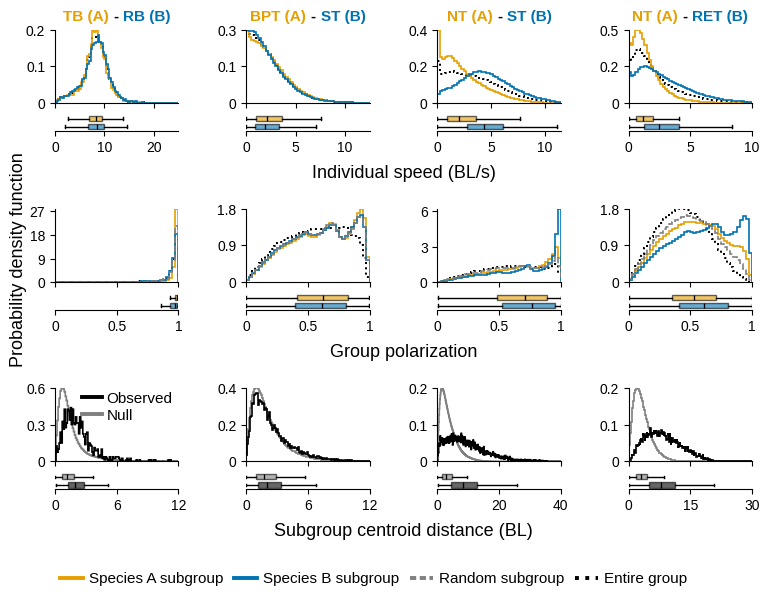

In [3]:
WIDTH, FIG_H, BOX_RATIO = 8.27, 11.69 / 2 + 0.25, 0.22   # A4 width, figure height (in, + room for the titles), box-plot / histogram height
SPEED_XLIM = [(0, 25), (0, 12.5), (0, 11.5), (0, 10)]
CD_XLIM = [(0, 12), (0, 12), (0, 40), (0, 30)]
XLABELS = ["Individual speed (BL/s)", "Group polarization", "Subgroup centroid distance (BL)"]
L, R, T, B, GAP = 0.95, 0.35, 0.45, 1.05, 0.78            # margins and gap between rows (in)
hist_h = (FIG_H - T - B - 2 * GAP - 0.15) / (3 + 3 * BOX_RATIO); box_h = BOX_RATIO * hist_h
row_h = hist_h + box_h + 0.05
H = T + B + 3 * row_h + 2 * GAP
fig = plt.figure(figsize=(WIDTH, H))
outer = GridSpec(3, 4, figure=fig, hspace=GAP / row_h, wspace=0.55, left=L / WIDTH, right=1 - R / WIDTH, bottom=B / H, top=1 - T / H)
axes = [[hist_and_box(fig, outer[i, j], hist_h, box_h) for j in range(4)] for i in range(3)]
for j, (a, b) in enumerate(PAIRS):
    r = res[(a, b)]
    # row 1: speed of the subgroups and the entire group
    ax, axb = axes[0][j]
    p995 = np.percentile(r["speed_all"], 99.5)
    edges, xl = np.arange(0, r["speed_all"].max() + p995 / 50, p995 / 50), SPEED_XLIM[j]
    hs = [rel_hist(ax, r[k], edges, color=c, ls=ls, lw=w) for k, c, ls, w in
          (("speed_all", "k", ":", lw * 1.2), ("speed_A", COL["A"], "-", lw), ("speed_B", COL["B"], "-", lw))]
    ax.set_xlim(*xl); set_y_to_max(ax, max(visible_max(h, edges, xl) for h in hs))
    draw_box(axb, [box_stats(r["speed_A"], a), box_stats(r["speed_B"], b)], [COL["A"], COL["B"]])
    axb.locator_params(axis="x", nbins=3, integer=True)
    # row 2: polarization of the subgroups, the entire group and 8 random fish
    ax, axb = axes[1][j]
    edges = np.arange(0, 1.0125, 0.025)
    hs = [rel_hist(ax, r[k], edges, color=c, ls=ls, lw=w) for k, c, ls, w in
          (("pol", "k", ":", lw * 1.2), ("pol_A", COL["A"], "-", lw), ("pol_B", COL["B"], "-", lw), ("pol_rand8", COL["rand8"], "--", lw))]
    ax.set_xlim(0, 1); set_y_to_max(ax, max(h.max() for h in hs))
    draw_box(axb, [box_stats(r["pol_A"], a), box_stats(r["pol_B"], b)], [COL["A"], COL["B"]])
    axb.set_xticks([0, 0.5, 1]); axb.set_xticklabels(["0", "0.5", "1"])
    # row 3: centroid distance, observed vs null
    ax, axb = axes[2][j]
    e, xl = r["cd_edges"], CD_XLIM[j]
    h_null = ax.stairs(r["cd_null"] / (r["cd_null"].sum() * np.diff(e)), e, color=COL["null"], lw=lw).get_data().values
    h_obs = rel_hist(ax, r["cd_obs"], e, color=COL["obs"], lw=lw)
    ax.set_xlim(*xl); set_y_to_max(ax, max(visible_max(h_null, e, xl), visible_max(h_obs, e, xl)))
    draw_box(axb, [box_stats_from_counts(r["cd_null"], e, "Null"), box_stats(r["cd_obs"], "Observed")], [COL["null"], COL["obs"]])
    axb.set_xticks([0, xl[1] / 2, xl[1]]); axb.set_xticklabels([f"{t:g}" for t in (0, xl[1] / 2, xl[1])])
for i, row in enumerate(axes):
    for ax, axb in row:
        style(ax); ax.tick_params(labelbottom=False)
    p0, p1 = row[0][1].get_position(), row[-1][1].get_position()
    fig.text((p0.x0 + p1.x1) / 2, p0.y0 - 0.34 / H, XLABELS[i], ha="center", va="top", fontsize=FONT)        # x label per row
top, bot = axes[0][0][0].get_position().y1, axes[2][0][1].get_position().y0
fig.text(0.5 / WIDTH, (top + bot) / 2, "Probability density function", rotation=90, ha="left", va="center", fontsize=FONT)
line = lambda c, ls, lab: Line2D([], [], color=c, ls=ls, lw=2.8, label=lab)
axes[2][0][0].legend(handles=[line(COL["obs"], "-", "Observed"), line(COL["null"], "-", "Null")], loc="upper right", bbox_to_anchor=(1, 1.04),
                     frameon=False, fontsize=11, handlelength=1.3, handletextpad=0.3, labelspacing=0.2, borderaxespad=0)
fig.legend(handles=[line(COL["A"], "-", "Species A subgroup"), line(COL["B"], "-", "Species B subgroup"),
                    line(COL["rand8"], (0, (1.6, 0.9)), "Random subgroup"), line("k", ":", "Entire group")],
           loc="lower center", bbox_to_anchor=(0.5, 0.02 / H), ncol=4, frameon=False, fontsize=11, handlelength=1.5,
           handletextpad=0.4, columnspacing=0.7, borderaxespad=0)
fig.canvas.draw(); rend = fig.canvas.get_renderer()
for (ax, _), (a, b) in zip(axes[0], PAIRS):                       # bold two-colour column titles, e.g. TB (A) - RB (B), centred above the top row
    bb = ax.get_position()
    ts = [fig.text(0, bb.y1 + 0.06 / H, s, color=c, fontsize=11, fontweight="bold", va="bottom")
          for s, c in ((f"{a} (A)", COL["A"]), ("-", "k"), (f"{b} (B)", COL["B"]))]
    w, gap = [t.get_window_extent(rend).width / fig.dpi / WIDTH for t in ts], 3.3 / 72 / WIDTH
    x = (bb.x0 + bb.x1) / 2 - (sum(w) + 2 * gap) / 2
    for t, wi in zip(ts, w):
        t.set_x(x); x += wi + gap
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(OUT, f"mixed_species_group_properties_gs16.{ext}"), dpi=300)
plt.show()